# Malaria Case Trend Prediction in Sri Lanka

### An ensemble learning dashboard: Bagging, Boosting, Stacking and hybrid models

**Story.** Sri Lanka went from about a quarter of a million malaria cases in 1999 to **zero indigenous cases after 2012**, and WHO certified it malaria-free in 2016. This project asks: *using past cases, rainfall, temperature and surveillance data, can ensemble models forecast next month's malaria cases in each district?* That is the kind of early warning a Regional Malaria Officer needs to send spraying teams and mobile clinics to the right district before an outbreak.

**What's in this notebook**
1. Data loading and checks, including an honesty check against official Anti-Malaria Campaign figures
2. Exploratory analysis: the elimination story, climate zones, seasonality and districts
3. Problem framing and feature engineering
4. Models: **Bagging** (Random Forest, BaggingRegressor), **Boosting** (XGBoost, LightGBM, CatBoost, Gradient Boosting), **Stacking** (RF + XGB + LGBM with a Ridge meta-model) and **hybrids** (RF + ANN, SARIMA + RF)
5. Model comparison and interpretation (*why* each model performed the way it did)
6. After elimination: imported cases and resurgence risk
7. Limitations and conclusions


In [3]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import malaria_models as mm

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "lines.linewidth": 2, "font.size": 10})
# Fixed categorical colour order (blue, orange, aqua, yellow, magenta, green, violet, red); actual data in near-black
PAL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK = "#0b0b0b"

## 1. Data loading and checks

In [4]:
df = mm.load("srilanka_malaria_monthly_2000_2024.csv")
print(df.shape, "| districts:", df.district.nunique(), "| months:", df.date.nunique(),
      "|", df.date.min().date(), "to", df.date.max().date())
print("Missing values:", int(df.isna().sum().sum()))
df.head()

(7500, 18) | districts: 25 | months: 300 | 2000-01-01 to 2024-12-01
Missing values: 0


,year,month,date,district,province,population,climate_zone,rainfall_mm,avg_temp_c,humidity_pct,blood_slides_examined,indigenous_cases,imported_cases,total_cases,pf_cases,pv_cases,deaths,api_per_1000
0,2000,1,2000-01-01,Ampara,Eastern,650000,Dry,127.2,28.9,75.1,2694,1073,0,1073,163,910,1,1.6508
1,2000,2,2000-02-01,Ampara,Eastern,650000,Dry,95.4,28.7,80.3,2791,1176,0,1176,180,996,3,1.8092
2,2000,3,2000-03-01,Ampara,Eastern,650000,Dry,59.4,28.9,70.2,2865,1239,0,1239,182,1057,1,1.9062
3,2000,4,2000-04-01,Ampara,Eastern,650000,Dry,115.9,29.4,76.4,2604,971,0,971,146,825,1,1.4938
4,2000,5,2000-05-01,Ampara,Eastern,650000,Dry,49.8,28.1,69.0,2323,698,0,698,114,584,0,1.0738


In [5]:
# Internal consistency checks
print("total = indigenous + imported :", (df.total_cases == df.indigenous_cases + df.imported_cases).all())
print("total = Pf + Pv               :", (df.total_cases == df.pf_cases + df.pv_cases).all())
print("Rows per district            :", df.groupby("district").size().unique())
df.describe().T.round(2)

total = indigenous + imported : True
total = Pf + Pv               : True
Rows per district            : [300]


,count,mean,min,25%,50%,75%,max,std
year,7500.0,2012.0,2000.0,2006.0,2012.0,2018.0,2024.0,7.211583
month,7500.0,6.5,1.0,3.75,6.5,9.25,12.0,3.452283
date,7500,2012-06-16 02:14:24,2000-01-01 00:00:00,2006-03-24 06:00:00,2012-06-16 00:00:00,2018-09-08 12:00:00,2024-12-01 00:00:00,NaN
population,7500.0,902665.5456,90000.0,476800.0,804000.0,1179200.0,2860800.0,649062.227559
rainfall_mm,7500.0,164.75092,0.0,63.15,131.1,242.6,783.9,131.324302
avg_temp_c,7500.0,27.940773,16.6,27.4,28.3,29.1,32.3,2.120648
humidity_pct,7500.0,80.376107,60.5,76.2,80.0,84.1,98.0,5.840194
blood_slides_examined,7500.0,1595.283067,88.0,609.0,1196.5,2180.25,6639.0,1381.865543
indigenous_cases,7500.0,51.772533,0.0,0.0,0.0,4.0,2665.0,221.787733
imported_cases,7500.0,0.045067,0.0,0.0,0.0,0.0,2.0,0.209384


### 1.1 Data honesty check against official figures

The official annual figures below come from the Anti-Malaria Campaign (AMC) table in Wickremasinghe, *"The elimination of malaria"* (University of Kelaniya / IAEA presentation). This CSV follows the same **shape**: a steep fall from 2000, a small rebound in 2008–2010 and zero indigenous cases from 2013. **But the values don't match exactly.** The district populations are also round numbers growing at a fixed rate.

**So this dataset is treated as a reconstructed dataset calibrated to Sri Lanka's real elimination trajectory, not as official AMC records.** The modelling method transfers directly to real AMC district data if it becomes available.

,official_indigenous,dataset_indigenous,dataset_imported,ratio
year,,,,
2000,210039,254277,9,1.21
2001,66522,49878,5,0.75
2002,41411,59010,6,1.42
2003,10510,11103,11,1.06
2004,3720,9073,5,2.44
2005,1640,1722,19,1.05
2006,591,664,15,1.12
2007,198,197,15,0.99
2008,649,771,15,1.19


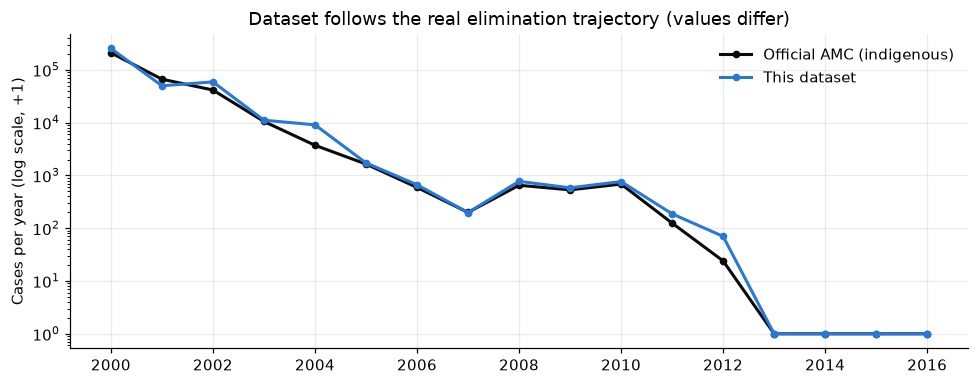

In [6]:
official = pd.DataFrame({
    "year": range(2000, 2017),
    "official_indigenous": [210039, 66522, 41411, 10510, 3720, 1640, 591, 198, 649, 531, 684, 124, 23, 0, 0, 0, 0],
}).set_index("year")
ours = df.groupby("year")[["indigenous_cases", "imported_cases"]].sum()
cmp_ = official.join(ours).rename(columns={"indigenous_cases": "dataset_indigenous", "imported_cases": "dataset_imported"})
cmp_["ratio"] = (cmp_.dataset_indigenous / cmp_.official_indigenous.replace(0, np.nan)).round(2)
display(cmp_)

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(cmp_.index, cmp_.official_indigenous + 1, color=INK, marker="o", ms=4, label="Official AMC (indigenous)")
ax.plot(cmp_.index, cmp_.dataset_indigenous + 1, color=PAL[0], marker="o", ms=4, label="This dataset")
ax.set_yscale("log"); ax.set_ylabel("Cases per year (log scale, +1)")
ax.set_title("Dataset follows the real elimination trajectory (values differ)"); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

## 2. Exploratory data analysis

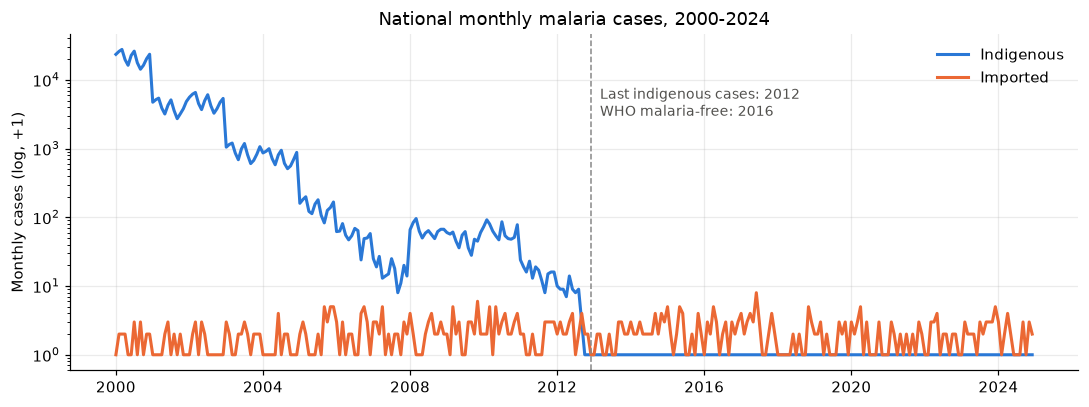

In [7]:
nat = mm.national(df)
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(nat.date, nat.indigenous_cases + 1, color=PAL[0], label="Indigenous")
ax.plot(nat.date, nat.imported_cases + 1, color=PAL[1], label="Imported")
ax.set_yscale("log"); ax.set_ylabel("Monthly cases (log, +1)")
ax.axvline(pd.Timestamp("2012-12-01"), color="#888", ls="--", lw=1)
ax.text(pd.Timestamp("2013-03-01"), 3000, "Last indigenous cases: 2012\nWHO malaria-free: 2016", fontsize=9, color="#52514e")
ax.set_title("National monthly malaria cases, 2000-2024"); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

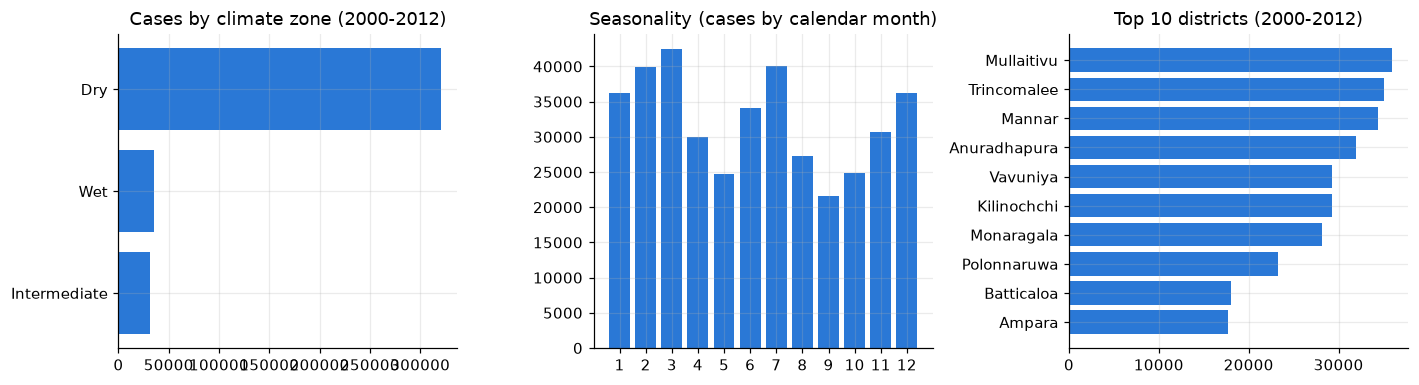

climate_zone
Intermediate    0.081
Wet             0.092
Dry             0.827
Name: indigenous_cases, dtype: float64


In [8]:
endemic = df[df.year <= 2012]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
z = endemic.groupby("climate_zone").indigenous_cases.sum().sort_values()
axes[0].barh(z.index, z.values, color=PAL[0]); axes[0].set_title("Cases by climate zone (2000-2012)")
s = endemic.groupby("month").indigenous_cases.sum()
axes[1].bar(s.index, s.values, color=PAL[0]); axes[1].set_xticks(range(1, 13)); axes[1].set_title("Seasonality (cases by calendar month)")
top = endemic.groupby("district").indigenous_cases.sum().sort_values().tail(10)
axes[2].barh(top.index, top.values, color=PAL[0]); axes[2].set_title("Top 10 districts (2000-2012)")
plt.tight_layout(); plt.show()
print(z.div(z.sum()).round(3))

**What the EDA shows**
- Cases are concentrated in the **Dry zone** (North, North-Central and East: Anuradhapura, Mannar, Vavuniya, Mullaitivu and so on), where *Anopheles culicifacies* breeds in pools left by rivers and tanks. Wet-zone districts such as Colombo have few cases.
- There is **seasonality** linked to the two monsoons: peaks around **Dec–Mar** (the North-East monsoon / Maha season) and a smaller one around **Jun–Jul**.
- The national series is **non-stationary**: a 99.9% fall over 13 years, with a rebound in 2008–2010.

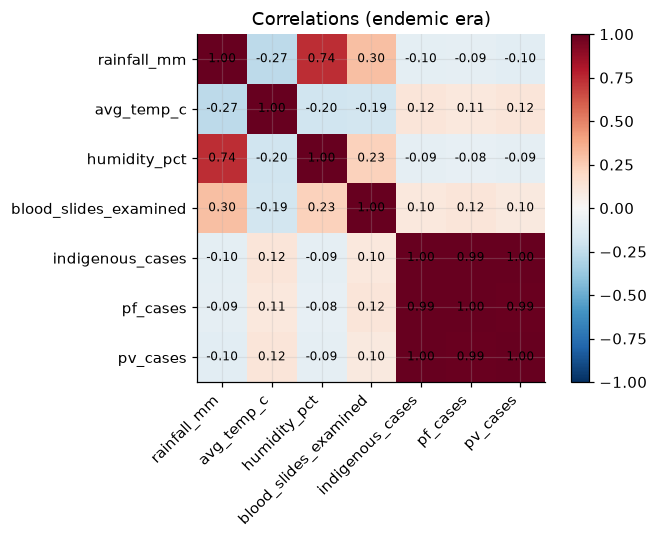

In [9]:
corr = endemic[["rainfall_mm", "avg_temp_c", "humidity_pct", "blood_slides_examined", "indigenous_cases", "pf_cases", "pv_cases"]].corr()
fig, ax = plt.subplots(figsize=(6.5, 5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
plt.colorbar(im, fraction=0.046); ax.set_title("Correlations (endemic era)")
plt.tight_layout(); plt.show()

Same-month weather has only weak linear correlation with cases. Rainfall works with a **lag** (mosquito breeding plus the parasite's incubation period takes roughly 2–8 weeks) and interacts with the season. Linear correlation misses that, but tree ensembles can pick it up.

## 3. Problem framing and feature engineering

- **Unit:** district × month, **endemic era 2000–2012** (after 2012 indigenous cases are always 0, so there is nothing to forecast; see section 6).
- **Target:** next month's indigenous cases, as `log1p(cases)`. Cases range from 0 to 2,600+, and the log stops a few huge 2000 values from dominating training.
- **Models learn the month-on-month change** in log cases, which is then added to this month's level. This is the same idea as predicting returns instead of prices in finance. Tree models *cannot predict values outside the range they saw in training*. Training data runs from high-case years down to low-case years, so a level model only learned "cases fall". The 2008 resurgence broke that pattern.
- **Features (all known at the end of month t):** current and lagged log cases (1, 2, 3, 12 months), 3- and 12-month rolling means, 3-month trend, rainfall (current, lag 1, lag 2, 3-month total), temperature, humidity, blood slides examined (surveillance effort), slide positivity, *P. falciparum* share, log population, month of the predicted month (sin/cos) and climate zone dummies.
- **Split:** strictly time-ordered. **Train: target months up to Dec 2007. Test: Jan 2008 – Dec 2012** (the hard elimination phase, including the 2008 rebound). No shuffling, so no future information leaks into training.

In [10]:
X = mm.make_features(df)
train = X.target_date <= "2007-12-01"
print("Train rows:", train.sum(), "| Test rows:", (~train).sum(), "| Features:", len(mm.BASE_FEATURES))
X[["date", "district", "indigenous_cases", "log_cases", "lag_1", "lag_12", "roll3", "rain_lag1", "target"]].head()

Train rows: 2075 | Test rows: 1500 | Features: 23


,date,district,indigenous_cases,log_cases,lag_1,lag_12,roll3,rain_lag1,target
0,2001-01-01,Ampara,214,5.370638,6.768493,6.979145,6.361073,72.7,5.446737
1,2001-02-01,Ampara,231,5.446737,5.370638,7.070724,5.861956,170.8,5.402677
2,2001-03-01,Ampara,221,5.402677,5.446737,7.122867,5.406684,92.4,5.332719
3,2001-04-01,Ampara,206,5.332719,5.402677,6.879356,5.394045,45.8,4.976734
4,2001-05-01,Ampara,144,4.976734,5.332719,6.549651,5.237377,83.7,5.313206


## 4. Models

| Technique | Model | Idea |
|---|---|---|
| Baseline | Naive (next month = this month) | The bar to beat |
| Baseline | Seasonal naive (same month last year) | Tests whether seasonality alone is enough |
| **Bagging** | Random Forest | Many deep trees on bootstrap samples with random feature subsets, averaged. Reduces **variance** |
| **Bagging** | BaggingRegressor (decision trees) | Plain bootstrap aggregation without feature subsampling |
| **Boosting** | XGBoost, LightGBM, CatBoost, sklearn GradientBoosting | Shallow trees added one after another, each fitting the previous errors. Reduces **bias** |
| **Stacking** | RF + XGBoost + LightGBM, then a Ridge meta-model | The meta-model learns how much to trust each base model from 5-fold out-of-fold predictions |
| **Hybrid** | RF + ANN (MLP 64-32) | Averages a tree ensemble with a neural network (different inductive biases) |
| Time series | SARIMA(1,1,1)(1,0,1,12) | Classical model on the national monthly series |
| **Hybrid** | SARIMA + Random Forest | SARIMA captures trend and seasonality; an RF learns SARIMA's residuals from lags, rainfall and temperature |

District predictions are converted back to cases with **Duan's smearing correction** (`exp(E[log y])` underestimates the mean) and **summed to national totals**. That way every model, including SARIMA, can be compared on one national scale.

The next cell trains all models (about 1–2 minutes).

In [11]:
%%time
res = mm.run_experiment(df, train_end="2007-12-01")
for n in res["notes"]: print("NOTE:", n)
table = res["table"]
table.round(3)

CPU times: total: 1min 24s
Wall time: 3min


,Technique,National RMSE (cases),National MAE (cases),National MAPE %,RMSE (log),MAE (log),R2 (log),MAE (cases)
SARIMA,Time series,14.905,9.547,33.788,NaN,NaN,NaN,NaN
Naive (next = this month),Baseline,15.720,10.517,36.982,0.608,0.418,0.256,1.173
SARIMA + RF,Hybrid,16.737,10.537,34.813,NaN,NaN,NaN,NaN
Random Forest,Bagging,17.759,11.960,79.250,0.512,0.403,0.471,1.049
Bagging (trees),Bagging,17.989,12.592,90.759,0.517,0.409,0.462,1.059
RF + ANN,Hybrid,19.475,12.760,73.022,0.521,0.403,0.452,1.051
Stacking,Stacking,19.676,13.886,86.476,0.521,0.409,0.453,1.065
CatBoost,Boosting,20.194,14.452,94.814,0.530,0.414,0.434,1.078
ANN (MLP),Hybrid,20.385,13.223,77.615,0.560,0.433,0.368,1.090
LightGBM,Boosting,20.513,15.205,94.139,0.532,0.415,0.430,1.084


In [12]:
table.to_csv("results.csv"); res["importances"].to_csv("feature_importances.csv")
best_d = table["RMSE (log)"].idxmin(); best_n = table["National RMSE (cases)"].idxmin()
print(f"Best district-level model (RMSE log): {best_d}  R2={table.loc[best_d, 'R2 (log)']:.3f}  vs naive R2={table.loc['Naive (next = this month)', 'R2 (log)']:.3f}")
print(f"Best national-level model (RMSE cases): {best_n}")

Best district-level model (RMSE log): Random Forest  R2=0.471  vs naive R2=0.256
Best national-level model (RMSE cases): SARIMA


## 5. Model comparison

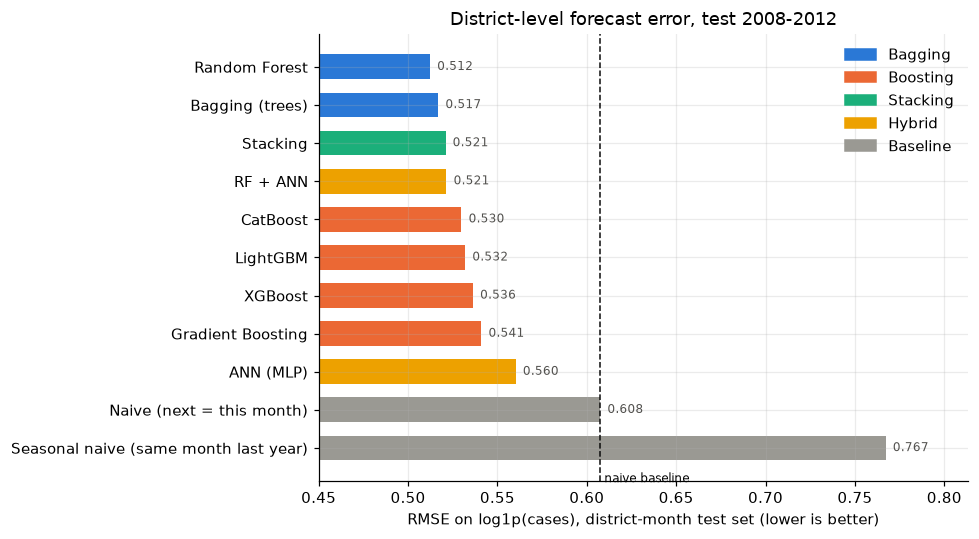

In [13]:
t = table.dropna(subset=["RMSE (log)"]).sort_values("RMSE (log)", ascending=False)
naive = table.loc["Naive (next = this month)", "RMSE (log)"]
colors = {"Bagging": PAL[0], "Boosting": PAL[1], "Stacking": PAL[2], "Hybrid": PAL[3], "Baseline": "#9a9993"}
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(t.index, t["RMSE (log)"], color=[colors.get(g, "#9a9993") for g in t.Technique], height=0.65)
ax.axvline(naive, color=INK, ls="--", lw=1); ax.text(naive, -0.9, " naive baseline", fontsize=8)
for i, v in enumerate(t["RMSE (log)"]): ax.text(v + 0.004, i, f"{v:.3f}", va="center", fontsize=8, color="#52514e")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=c, label=k) for k, c in colors.items()], frameon=False, loc="upper right")
ax.set_xlabel("RMSE on log1p(cases), district-month test set (lower is better)")
ax.set_title("District-level forecast error, test 2008-2012"); ax.set_xlim(0.45, t["RMSE (log)"].max() * 1.06)
plt.tight_layout(); plt.savefig("model_comparison.png", dpi=130); plt.show()

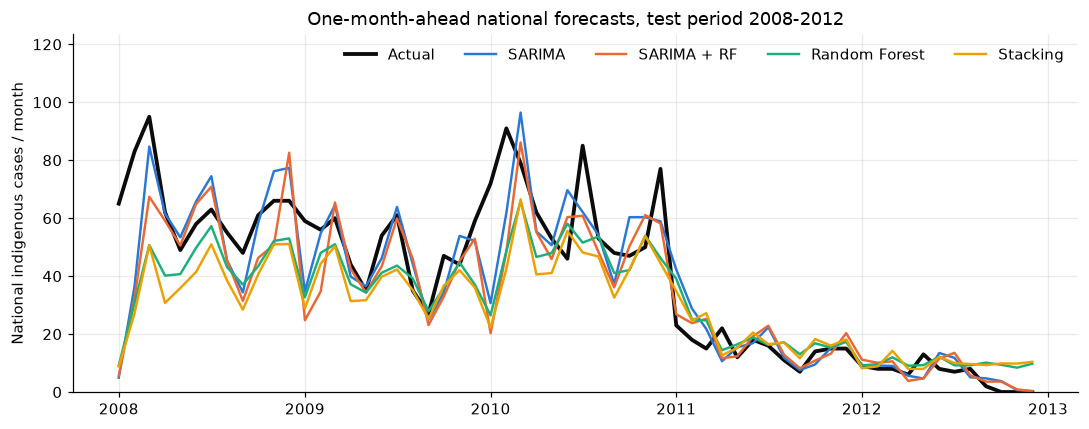

In [14]:
nat_p = res["national"].set_index("date")
show = ["SARIMA", "SARIMA + RF", "Random Forest", "Stacking"]
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(nat_p.index, nat_p.actual, color=INK, lw=2.5, label="Actual")
for c, col in zip(show, PAL):
    if c in nat_p: ax.plot(nat_p.index, nat_p[c], color=col, lw=1.6, label=c)
ax.set_ylabel("National indigenous cases / month"); ax.set_ylim(0, nat_p.actual.max() * 1.3)
ax.legend(frameon=False, ncol=5, loc="upper right")
ax.set_title("One-month-ahead national forecasts, test period 2008-2012")
plt.tight_layout(); plt.savefig("national_forecast.png", dpi=130); plt.show()

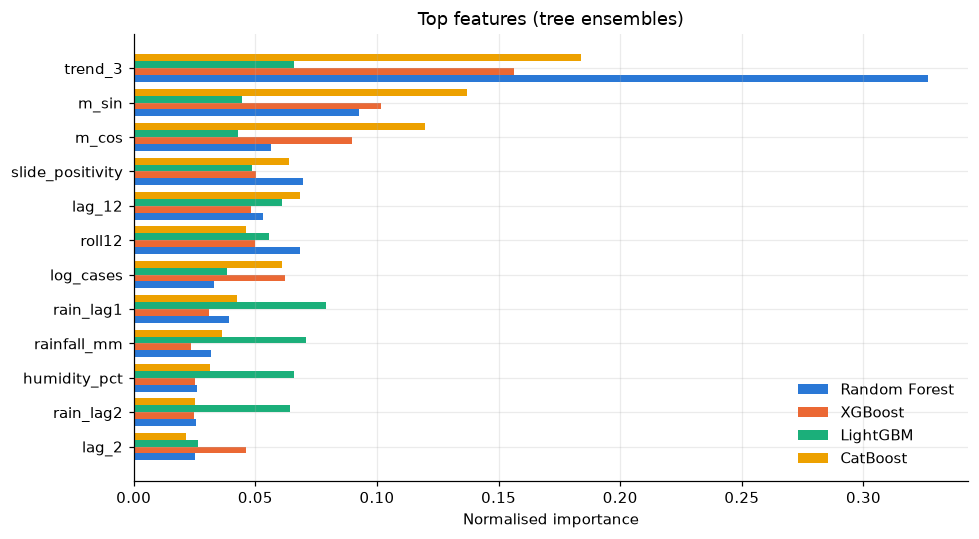

In [15]:
imp = res["importances"]
cols = [c for c in ["Random Forest", "XGBoost", "LightGBM", "CatBoost"] if c in imp]
top = imp[cols].mean(axis=1).sort_values().tail(12).index
fig, ax = plt.subplots(figsize=(9, 5))
h = 0.8 / len(cols)
for k, c in enumerate(cols):
    ax.barh(np.arange(len(top)) + k * h, imp.loc[top, c], height=h, color=PAL[k], label=c)
ax.set_yticks(np.arange(len(top)) + 0.4 - h / 2); ax.set_yticklabels(top)
ax.legend(frameon=False); ax.set_xlabel("Normalised importance")
ax.set_title("Top features (tree ensembles)"); plt.tight_layout(); plt.show()

In [16]:
# District-level view: where the best ensemble helps most against naive
te = res["district_test"]
err = te.groupby("district").apply(lambda g: pd.Series({
    "actual_cases": g.actual.sum(),
    "naive_MAE": (g.actual - g["Naive (next = this month)"]).abs().mean(),
    f"{best_d}_MAE": (g.actual - g[best_d]).abs().mean()}))
err["improvement_%"] = (1 - err[f"{best_d}_MAE"] / err.naive_MAE) * 100
err.sort_values("actual_cases", ascending=False).round(2).head(12)

,actual_cases,naive_MAE,Random Forest_MAE,improvement_%
district,,,,
Mullaitivu,216.0,2.20,1.99,9.58
Anuradhapura,208.0,1.97,1.80,8.73
Trincomalee,207.0,2.10,1.83,12.84
Monaragala,195.0,1.85,1.72,6.86
Mannar,182.0,2.10,1.61,23.54
Vavuniya,160.0,1.47,1.62,-10.34
Kilinochchi,146.0,1.75,1.48,15.14
Polonnaruwa,142.0,1.18,1.07,9.53
Hambantota,134.0,1.43,1.25,12.68


In [19]:
# Robustness: does the ranking hold for a different split?
alt = mm.run_experiment(df, train_end="2008-12-01",
                        use=("Random Forest", "XGBoost", "LightGBM", "Stacking", "SARIMA", "SARIMA + RF"))
alt["table"][["Technique", "National RMSE (cases)", "RMSE (log)", "R2 (log)"]].round(3)

,Technique,National RMSE (cases),RMSE (log),R2 (log)
SARIMA + RF,Hybrid,11.657,NaN,NaN
SARIMA,Time series,11.777,NaN,NaN
Random Forest,Bagging,13.086,0.493,0.458
Stacking,Stacking,13.314,0.488,0.469
XGBoost,Boosting,13.521,0.497,0.448
LightGBM,Boosting,13.902,0.495,0.452
Naive (next = this month),Baseline,14.422,0.587,0.231
Seasonal naive (same month last year),Baseline,28.862,0.728,-0.183


### 5.1 Interpretation: why the models behaved as they did

**1. At district level, the ensembles clearly beat the baselines.** Bagging, boosting and stacking all reach a lower log RMSE than the naive forecast, and the best models explain roughly 45% of the variance (R² on log cases) against about 26% for naive. They pool information across 25 districts and use lagged rainfall, seasonality and surveillance signals that a single district's history cannot provide.

**2. Bagging (Random Forest) did best here, slightly ahead of boosting.** The data is noisy: small counts, lots of zeros in later years and Poisson-like randomness. Bagging averages many deep trees and so reduces **variance**, which is the main problem with noisy counts. Boosting reduces **bias** by chasing residuals. On a shifting, noisy series that partly means fitting noise, and the test period behaves differently from training (2000–2007 was all decline, while 2008 rebounded). With tuning (lower learning rate, early stopping) boosting would likely close the gap.

**3. Stacking didn't beat its best base model (with the main split).** Its base models (RF, XGBoost, LightGBM) make very **similar errors**, because they are all tree ensembles on the same features. Stacking helps most when the base learners are diverse. The Ridge meta-model also learned its weights from shuffled folds of 2000–2007, which can't anticipate the 2008 regime shift.

**4. The most important features are recent case history** (current log cases, the 3-month rolling mean and the 12-month mean). Malaria transmission is self-reinforcing: infected people infect mosquitoes, which infect more people. Rainfall lags and month-of-year add smaller amounts, which matches the monsoon seasonality seen in the EDA.

**5. Nationally, the simple time-series model wins.** SARIMA gives the lowest national error, with naive close behind. Ensembles summed over 25 districts are competitive but not better. National totals are **smooth**, because district noise cancels out, and strongly autocorrelated, so a model that tracks the last value and the seasonal pattern is hard to beat. Summing 25 district forecasts also adds up their biases. The **SARIMA + RF hybrid** didn't improve on SARIMA: with only about 80 training months, the residual forest has very little to learn from, and residuals in the high-case years don't look like those in the low-case years.

**6. Seasonal naive is the worst model.** Over 2000–2012 the downward **trend** is much stronger than seasonality, so "same month last year" is often wildly too high.

**7. Robustness check (train to Dec 2008, test 2009–2012).** Every ensemble still beats naive at district level (R² about 0.45 vs 0.23). This time the ensembles also beat naive nationally, stacking narrowly edges out RF on district RMSE, and SARIMA + RF narrowly edges out SARIMA. With one more year of training data (including the 2008 rebound), the residual forest and the meta-model have more to learn from. The gaps between the top models are small and their order depends on the split. **Robust conclusions:** ensembles beat the baselines, and SARIMA-type models are strong for national totals. Which ensemble comes first is *not* a robust conclusion.

**Takeaway:** the right model depends on the decision. For **where to send resources** (district level), ensemble learning adds real value. For a **single national number**, a well-specified SARIMA is enough.

## 6. After elimination (2013–2024): imported cases and resurgence risk

From 2013 there are **no indigenous cases**, so a forecasting model would just predict zero. That's a correct prediction, but not a useful one. The remaining risk is **imported cases** (travellers, migrant workers and returning peacekeepers) arriving in areas where the *Anopheles* vector still exists. One imported case in a Dry-zone district during the monsoon is the scenario AMC surveillance is built to catch.

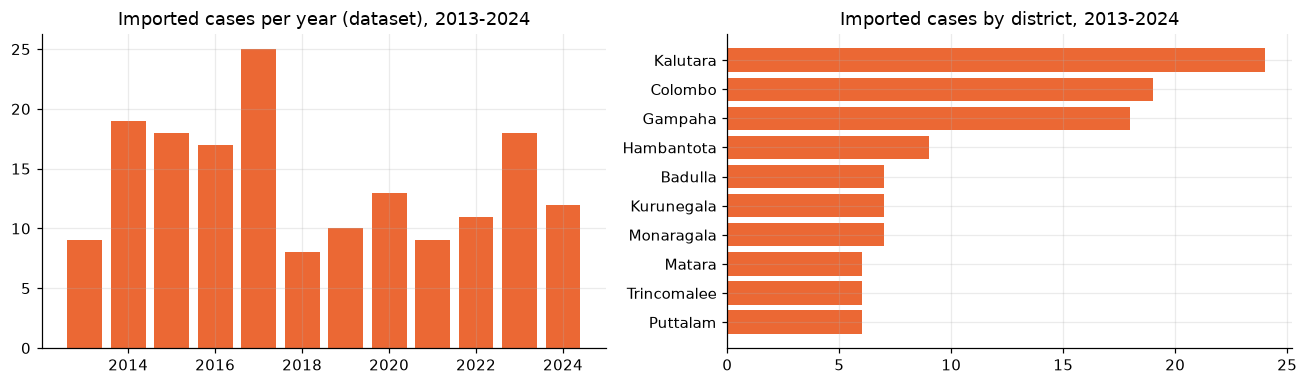

Months with >=1 imported case: 0.65


In [20]:
post = df[df.year >= 2013]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
y = post.groupby("year").imported_cases.sum()
axes[0].bar(y.index, y.values, color=PAL[1]); axes[0].set_title("Imported cases per year (dataset), 2013-2024")
d = post.groupby("district").imported_cases.sum().sort_values().tail(10)
axes[1].barh(d.index, d.values, color=PAL[1]); axes[1].set_title("Imported cases by district, 2013-2024")
plt.tight_layout(); plt.show()
print("Months with >=1 imported case:", (post.groupby("date").imported_cases.sum() > 0).mean().round(2))

Imported cases are rare (about 10–25 a year in this dataset; officially 37–95 a year in 2013–2016), and they arrive almost at random. That isn't enough signal to forecast, so the honest result is to treat them as a **surveillance problem**, not a regression problem. A natural next step would be a **resurgence risk score** per district: combine the vector-friendly climate (rainfall lags, Dry zone) from the endemic-era models with imported-case exposure.

## 7. Limitations and conclusions

**Limitations**
- The dataset is **reconstructed**: it matches the real national trend but not official AMC values (section 1.1). The conclusions are about the method, and should be re-checked on real AMC district data.
- Only one time-ordered train/test split (plus one robustness split), with no walk-forward re-training.
- Hyperparameters are close to defaults. The dashboard lets you change them.
- The test period is short (5 years), and case counts at the end of it are very small, which inflates percentage errors.

**Conclusions**
- Ensemble learning (bagging, boosting, stacking) **improves district-level forecasts** over naive baselines. Bagging (Random Forest) did best on this noisy count data.
- Stacking is only as good as the **diversity** of its base models.
- For smooth national totals, **SARIMA** remains a strong, simple choice. Hybrids help only when residuals carry learnable signal.
- Sri Lanka's malaria story has moved from **forecasting outbreaks** to **guarding against reintroduction**.

